# Context-dependent remapping (Fig. 3)

Reproduces Fig. 3 (Sec. 2.5, Appendices I and M): the between-context similarity as a function
of the context separation $\Delta s$, and the rate maps of the same units at $s = 0$ and $s = 5$.

A scalar context enters as the spatial coordinates do, $p(x, y, s) = e^{xG_x + yG_y + sG_s}p_0$.
The spatial generators are metric-preserving (roots of unity, so grid fields) and the context
generator is similarity-preserving (Gaussian eigenvalues, so the similarity between contexts
decays as a Gaussian, Eq. 5).

The population is 50 hexagonal sets on one ring, each rotated by $\pi/150$ relative to the
previous one, with one context eigenvalue per subspace and a mixing matrix $R$ that mixes within
a set only (App. I). No two sets share a wavevector, so the pairwise phase relations within a
set are unchanged by the context shift while the fields of single units shift and deform
(App. M). The last section checks this.

$G_s$ commutes with $G_x$ and $G_y$ and all three are skew-symmetric, so the between-context
similarity at a fixed position does not depend on the position,
$p(x,y,s_1)^\top p(x,y,s_2) = p_0^\top e^{\Delta s\,G_s}p_0 = C(\Delta s)$. The scatter in the
similarity panel is rate map binning error.

$M = 3$, $N = 300$ and the shift $s = 0 \to 5$ are those of Fig. 3. The $20 \times 20$ arena and
the context range $[0, 5]$ are those of Appendix A. `SEED` fixes the context eigenvalues, $R$ and
the position sampling.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

from expmap.analysis import batch_inference, compute_ratemaps, periodic_cross_correlograms
from expmap.generators import (
    block_diag_skew,
    build_generators_with_context,
    gaussian_eigenvalues,
    roots_of_unity_eigenvalues,
)
from expmap.linalg import block_diagonal_orthogonal, starting_state
from expmap.model import RemappingModel
from expmap.plotting import ratemap_collage
from expmap.simulation import generate_uniform_positions

M = 3
N_SETS = 50  # N = 2 * M * N_SETS = 300
CONTEXT_SCALE = np.sqrt(2)  # standard deviation of the context eigenvalues, N(0, 2 sigma^2) with sigma = 1 (App. I)
ARENA_SIZE = 10
BINS = 32
BATCH_SIZE, BATCHES = 50, 500
CONTEXT_VALS = np.linspace(0, 5, 20)
SHOWN_SHIFT = 5.0  # the shift whose rate maps Fig. 3 shows
SEED = 0

# The panels are drawn at their printed size: the similarity panel and two 4 x 4 collages share
# the 5.5 in text width.
SIMILARITY_PANEL = (1.9, 1.2)  # inches
COLLAGE_SIZE = 1.15  # inches, each 4 x 4 collage
plt.rcParams.update(
    {
        "font.family": "serif",
        "font.serif": ["Times New Roman"],
        "mathtext.fontset": "stix",
        "svg.fonttype": "none",
        "font.size": 8,
        "axes.labelsize": 8,
        "xtick.labelsize": 7,
        "ytick.labelsize": 7,
    }
)

REPO_ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
FIGURE_DIR = REPO_ROOT / "figures"
FIGURE_DIR.mkdir(exist_ok=True)

In [2]:
N = 2 * M * N_SETS

# Hexagonal sets on the unit ring, each rotated by its own offset, so that no two subspaces
# share a wavevector. Subspaces are ordered set by set.
base = roots_of_unity_eigenvalues(M)
offsets = np.arange(N_SETS) * np.pi / (M * N_SETS)
phi = (offsets[:, None] + base[None, :]).ravel()
sigma_x = block_diag_skew(np.cos(phi))
sigma_y = block_diag_skew(np.sin(phi))

# One context eigenvalue per subspace.
ev_s = gaussian_eigenvalues(N, scale=CONTEXT_SCALE, seed=SEED)
sigma_s = block_diag_skew(ev_s)

# R mixes within a set only, so each unit belongs to one set.
R = block_diagonal_orthogonal(N_SETS, 2 * M, seed=SEED)
p0 = starting_state(R)
Gx, Gy, Gs = build_generators_with_context(sigma_x, sigma_y, sigma_s, R)

model = RemappingModel(Gx, Gy, Gs)

for name, G in [("Gx", Gx), ("Gy", Gy), ("Gs", Gs)]:
    assert torch.allclose(G, -G.T, atol=1e-6), f"{name} must be skew-symmetric"
assert torch.allclose(Gx @ Gy, Gy @ Gx, atol=1e-5), "Gx must commute with Gy"
assert torch.allclose(Gx @ Gs, Gs @ Gx, atol=1e-5), "Gs must commute with Gx"
assert torch.allclose(Gy @ Gs, Gs @ Gy, atol=1e-5), "Gs must commute with Gy"

# The condition of App. M: no two subspaces share a wavevector.
assert len(np.unique(np.round(phi, 6))) == M * N_SETS

print(f"N = {N} units")

N = 300 units


In [3]:
r_batch = generate_uniform_positions(BATCHES, BATCH_SIZE, ARENA_SIZE, seed=SEED)
r = np.concatenate(r_batch)

# The reference context, computed once for the whole sweep.
p_reference = batch_inference(model, r_batch, p0, context=0.0, progress=False)
ratemaps_c1 = compute_ratemaps(r[:, 0], r[:, 1], p_reference, bins=BINS)

print(f"||p|| = {np.linalg.norm(p_reference, axis=1).mean():.6f}")

||p|| = 1.000000


In [4]:
# The between-context similarity per rate map bin, for every context separation.
similarity_by_bin = []

for context in CONTEXT_VALS:
    p_shifted = batch_inference(model, r_batch, p0, context=float(context), progress=False)
    ratemaps_shifted = compute_ratemaps(r[:, 0], r[:, 1], p_shifted, bins=BINS)
    similarity_by_bin.append(np.nansum(ratemaps_c1 * ratemaps_shifted, axis=0))

similarity_by_bin = np.array(similarity_by_bin).reshape(len(CONTEXT_VALS), -1)
mean_similarity = np.nanmean(similarity_by_bin, axis=-1)

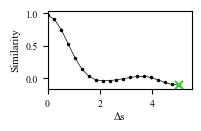

In [5]:
# Fig. 3, left: the per-bin similarity (gray), its mean over bins, and a cross at the shift
# whose rate maps the right-hand panels show.
plt.figure(figsize=SIMILARITY_PANEL, layout="constrained")
for i, ds in enumerate(CONTEXT_VALS):
    plt.scatter(ds * np.ones(similarity_by_bin.shape[-1]), similarity_by_bin[i], color="0.6", alpha=0.1, s=1, linewidths=0)
plt.plot(CONTEXT_VALS, mean_similarity, "k.-", linewidth=0.5, markersize=3)
shown = np.argmin(np.abs(CONTEXT_VALS - SHOWN_SHIFT))
plt.plot(SHOWN_SHIFT, mean_similarity[shown], "x", color="limegreen", markersize=6, markeredgewidth=1.5)
plt.xlabel("Δs", labelpad=2)
plt.ylabel("Similarity")
plt.xlim([0, 5.5])
plt.xticks([0, 2, 4])
plt.savefig(
    FIGURE_DIR / "Remapping_distinct_similarity.svg", dpi=300, transparent=True, bbox_inches="tight", pad_inches=0.02
)
plt.savefig(
    FIGURE_DIR / "Remapping_distinct_similarity.png", dpi=300, transparent=True, bbox_inches="tight", pad_inches=0.02
)

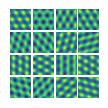

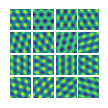

In [6]:
# Fig. 3, right: the same units at s = 0 and s = 5, four units from each of four sets, one set
# per row. Both collages share one color scale.
SHOWN_SETS = [0, 12, 25, 37]
shown_units = np.concatenate([2 * M * m + np.arange(4) for m in SHOWN_SETS])

p_c2 = batch_inference(model, r_batch, p0, context=SHOWN_SHIFT, progress=False)
ratemaps_c2 = compute_ratemaps(r[:, 0], r[:, 1], p_c2, bins=BINS)

vmin = min(np.nanmin(ratemaps_c1[shown_units]), np.nanmin(ratemaps_c2[shown_units]))
vmax = max(np.nanmax(ratemaps_c1[shown_units]), np.nanmax(ratemaps_c2[shown_units]))
for ratemaps, name in [
    (ratemaps_c1, "Remapping_distinct_ratemaps_s0"),
    (ratemaps_c2, "Remapping_distinct_ratemaps_s5"),
]:
    fig, _ = ratemap_collage(
        ratemaps[shown_units], rows=4, cols=4, figsize=(COLLAGE_SIZE, COLLAGE_SIZE), vmin=vmin, vmax=vmax
    )
    fig.savefig(FIGURE_DIR / f"{name}.svg", dpi=300, transparent=True, bbox_inches="tight", pad_inches=0.02)
    fig.savefig(FIGURE_DIR / f"{name}.png", dpi=300, transparent=True, bbox_inches="tight", pad_inches=0.02)

## Check against Eq. 5

Eq. 5 gives the between-context similarity in closed form,
$C(\Delta s) = \sum_i \alpha_{0,i}^2 \cos(\Delta s\,\lambda_{i,s})$ with uniform coefficients
$1/N$ per pair of components, and with Gaussian eigenvalues it approximates
$e^{-\sigma^2 \Delta s^2}$ (App. I). The difference between the mean over bins and Eq. 5 is
binning error, and the difference between Eq. 5 and the Gaussian is the Monte Carlo error of
$N/2 = 150$ eigenvalues.

max |binned mean - Eq. 5|     = 0.0308
rms |Eq. 5 - Gaussian|        = 0.0454
Monte Carlo error 1/sqrt(N/2) = 0.0816


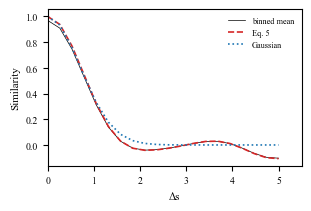

In [7]:
eq5 = np.array([np.sum((2 / N) * np.cos(ds * ev_s)) for ds in CONTEXT_VALS])
gaussian = np.exp(-(CONTEXT_SCALE**2) * CONTEXT_VALS**2 / 2)

print(f"max |binned mean - Eq. 5|     = {np.nanmax(np.abs(mean_similarity - eq5)):.4f}")
print(f"rms |Eq. 5 - Gaussian|        = {np.sqrt(np.mean((eq5 - gaussian) ** 2)):.4f}")
print(f"Monte Carlo error 1/sqrt(N/2) = {1 / np.sqrt(N // 2):.4f}")

fig, ax = plt.subplots(figsize=(3, 2), layout="constrained")
ax.plot(CONTEXT_VALS, mean_similarity, "k", linewidth=0.5, label="binned mean")
ax.plot(CONTEXT_VALS, eq5, "C3--", linewidth=1.2, label="Eq. 5")
ax.plot(CONTEXT_VALS, gaussian, "C0:", linewidth=1.2, label="Gaussian")
ax.set_xlabel("Δs")
ax.set_ylabel("Similarity")
ax.set_xlim([0, 5.5])
ax.legend(fontsize=6, frameon=False)

## Pairwise phase relations under the context shift

The cross-correlogram of two units $n$ and $m$ of a set is

$$
\chi_{nm}(\boldsymbol{\Delta}) = \tfrac{1}{2}\sum_i a_{n,i}\,a_{m,i}
  \cos(\mathbf{k}_i\cdot\boldsymbol{\Delta} + \psi_{m,i} - \psi_{n,i}),
$$

with no dependence on $s$ when every wavevector belongs to a single subspace (App. M). The
check below evaluates each set on one period of its own lattice, where the periodic
cross-correlogram is exact, and compares $s = 0$ with $s = 5$.

In [8]:
BOX_BINS = 32


def periodic_box(offset):
    """One period of the hexagonal lattice with unit wavenumber and wave directions offset + (0, 60, 120) degrees."""
    x = np.linspace(0, 4 * np.pi, BOX_BINS, endpoint=False)
    y = np.linspace(0, 4 * np.pi / np.sqrt(3), BOX_BINS, endpoint=False)
    X, Y = np.meshgrid(x, y, indexing="ij")
    c, s = np.cos(offset), np.sin(offset)
    positions = np.stack([c * X - s * Y, s * X + c * Y], axis=-1).reshape(-1, 2)
    return torch.tensor(positions, dtype=torch.float32)


def correlogram_change(positions, units):
    """Change in the normalized cross-correlograms of all pairs of units between s = 0 and SHOWN_SHIFT."""
    correlograms = []
    for context in (0.0, SHOWN_SHIFT):
        p = batch_inference(model, positions.split(64), p0, context=context, progress=False)[:, units]
        correlograms.append(periodic_cross_correlograms(p.T.reshape(len(units), BOX_BINS, BOX_BINS)))
    return np.abs(correlograms[0] - correlograms[1])


changes = np.array([correlogram_change(periodic_box(offsets[m]), 2 * M * m + np.arange(2 * M)) for m in SHOWN_SETS])
print(f"sets {SHOWN_SETS}: change in pairwise cross-correlograms max {changes.max():.1e}, median {np.median(changes):.1e}")

sets [0, 12, 25, 37]: change in pairwise cross-correlograms max 4.9e-07, median 7.5e-08
